# YES24 계절별 베스트셀러 도서 분야 EDA 보고서

| 항목 | 내용 |
|---|---|
| 데이터 파일 | `yes24_seasonal_raw.csv` (원본) → `yes24_seasonal_clean.csv` (정리본) |
| 데이터 출처 | YES24 국내도서 종합 월별 베스트셀러 (https://www.yes24.com/product/category/monthweekbestseller) |
| 수집 범위 | 2023년 1월 ~ 2025년 12월 (36개월), 매월 1~20위 (최대 720행) |
| 수집 방법 | `01_yes24_scraping.ipynb` — requests + BeautifulSoup으로 월별 목록(AJAX 주소 `BestSellerContents`)을 받고, 각 책 상세 페이지의 '카테고리 분류' 첫 경로에서 두 번째 단계(대분류)를 분야로 사용. 요청 간 1초 대기 |
| 계절 기준 | 봄 3~5월, 여름 6~8월, 가을 9~11월, 겨울 12~2월 |

**분석 질문**: 계절별 베스트셀러에 가장 많이 등장하는 도서 분야는 무엇이며, 계절에 따라 분야 구성이 달라지는가?
- 세부 질문 ① 1월에는 자기계발 분야 비중이 다른 달보다 높은가?
- 세부 질문 ② 여름에는 소설 분야 비중이 다른 계절보다 높은가?
- 세부 질문 ③ 계절 패턴이 2023·2024·2025년에 반복되는가? 소수의 히트작이 결과를 왜곡하지는 않는가?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (Windows: 맑은 고딕 / macOS: AppleGothic)
import platform
plt.rcParams["font.family"] = "Malgun Gothic" if platform.system() == "Windows" else "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

SEASONS = ["봄", "여름", "가을", "겨울"]
SEASON_COLORS = {"봄": "#8BC34A", "여름": "#2196F3", "가을": "#FF9800", "겨울": "#7E57C2"}

raw = pd.read_csv("yes24_seasonal_raw.csv", encoding="utf-8-sig", dtype={"상품번호": str})
df = raw.copy()
df.head()

,연도,월,계절,순위,상품번호,제목,저자,출판사,분야,카테고리경로
0,2023,1,겨울,1,115142458,만일 내가 인생을 다시 산다면 (35만 부 기념 스페셜 에디션),김혜남 저,메이븐,인문,국내도서 > 인문 > 주제로 읽는 인문학 > 노년 / 죽음
1,2023,1,겨울,2,116579452,스카이 버스,분당강쌤 저,다산에듀,가정 살림,국내도서 > 가정 살림 > 자녀교육 > 학습법일반
2,2023,1,겨울,3,116046489,생에 감사해,김혜자 저,수오서재,에세이,국내도서 > 에세이 > 명사/연예인 에세이
3,2023,1,겨울,4,99308021,불편한 편의점,김호연 저,나무옆의자,소설/시/희곡,국내도서 > 소설/시/희곡 > 한국소설 > 한국 장편소설
4,2023,1,겨울,5,111088149,불편한 편의점 2,김호연 저,나무옆의자,소설/시/희곡,국내도서 > 소설/시/희곡 > 한국소설 > 한국 장편소설


## 1. 데이터 개요

In [2]:
n_rows, n_cols = df.shape
n_full_dup = df.duplicated().sum()
n_months = df[["연도", "월"]].drop_duplicates().shape[0]
n_books = df["상품번호"].nunique()

print(f"행 수: {n_rows}, 열 수: {n_cols}")
print(f"완전 중복행 수: {n_full_dup}")
print(f"수집된 연·월 수: {n_months} / 목표 36개월")
print(f"서로 다른 책 수(상품번호 기준): {n_books}")
print(f"서로 다른 제목 수: {df['제목'].nunique()}")

행 수: 720, 열 수: 10
완전 중복행 수: 0
수집된 연·월 수: 36 / 목표 36개월
서로 다른 책 수(상품번호 기준): 304
서로 다른 제목 수: 304


**해석**
- 720행 × 10열로, 목표했던 36개월 × 20권 = 720행이 빠짐없이 수집되었습니다.
- 완전 중복행은 0개입니다.
- 서로 다른 책은 304권(상품번호·제목 모두 304개)으로, 720개 자리 중 상당수를 같은 책이 여러 달에 걸쳐 차지했습니다.

In [3]:
by_year = df["연도"].value_counts().sort_index().rename("권수").to_frame()
by_season = df["계절"].value_counts().reindex(SEASONS).rename("권수").to_frame()
display(by_year)
display(by_season)

,권수
연도,
2023,240
2024,240
2025,240


,권수
계절,
봄,180
여름,180
가을,180
겨울,180


**해석**
- 연도별 240권, 계절별 180권(3개월 × 20권 × 3년)으로 모두 같습니다.
- 계절마다 분모가 180으로 같아서 계절 간 **등장 횟수**를 그대로 비교해도 **비율**을 비교하는 것과 결과가 같습니다.

**주요 컬럼 설명**

| 컬럼 | 설명 |
|---|---|
| 연도, 월 | 베스트셀러 집계 연도와 월 |
| 계절 | 월 기준 계절 (봄 3~5, 여름 6~8, 가을 9~11, 겨울 12·1·2) |
| 순위 | 해당 월 종합 순위 (1~20) |
| 상품번호 | YES24 상품 고유번호 — 같은 책 판별 기준 |
| 제목, 저자, 출판사 | 목록 페이지에 표시된 도서 정보 |
| 분야 | 상세 페이지 카테고리 경로의 두 번째 단계(대분류). **분석의 핵심 변수** |
| 카테고리경로 | 분야를 뽑은 원래 경로 (예: 국내도서 > 소설/시/희곡 > 한국소설 > …) |

## 2. 구조 진단 (shape / info / describe)

In [4]:
print(df.shape)
df.info()

(720, 10)
<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   연도      720 non-null    int64
 1   월       720 non-null    int64
 2   계절      720 non-null    str  
 3   순위      720 non-null    int64
 4   상품번호    720 non-null    str  
 5   제목      720 non-null    str  
 6   저자      720 non-null    str  
 7   출판사     720 non-null    str  
 8   분야      720 non-null    str  
 9   카테고리경로  720 non-null    str  
dtypes: int64(3), str(7)
memory usage: 173.0 KB


**해석**
- 10개 컬럼 모두 720개 non-null로, 목록 단계에서 빈 값은 없습니다.
- 연도·월·순위는 int64, 상품번호는 앞자리 0이 사라지지 않도록 문자열로 읽었습니다.

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
연도,720.0,NaN,NaN,NaN,2024.0,0.817064,2023.0,2023.0,2024.0,2025.0,2025.0
월,720.0,NaN,NaN,NaN,6.5,3.454452,1.0,3.75,6.5,9.25,12.0
계절,720,4,겨울,180,NaN,NaN,NaN,NaN,NaN,NaN,NaN
순위,720.0,NaN,NaN,NaN,10.5,5.77029,1.0,5.75,10.5,15.25,20.0
상품번호,720,304,117014613,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
제목,720,304,세이노의 가르침,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
저자,720,225,최태성 저,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
출판사,720,133,YBM(와이비엠),39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
분야,720,17,소설/시/희곡,137,NaN,NaN,NaN,NaN,NaN,NaN,NaN
카테고리경로,720,101,국내도서 > 소설/시/희곡 > 한국소설 > 한국 장편소설,82,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**해석**
- 순위는 1~20(평균 10.5)으로 1~20위 범위 밖의 값은 없습니다.
- 가장 많이 등장한 책은 '세이노의 가르침'(21회)이고, 분야 최빈값은 '소설/시/희곡'(137회)입니다.
- 분야 고유값은 17개, 그 아래 카테고리 경로는 101가지입니다.

In [6]:
# 월별로 20권씩 수집됐는지 확인
month_cnt = df.pivot_table(index="연도", columns="월", values="상품번호", aggfunc="count")
display(month_cnt)
bad = month_cnt.stack()[lambda s: s != 20]
print("20권이 아닌 달:", "없음" if bad.empty else bad.to_dict())

월,1,2,3,4,5,6,7,8,9,10,11,12
연도,,,,,,,,,,,,
2023,20,20,20,20,20,20,20,20,20,20,20,20
2024,20,20,20,20,20,20,20,20,20,20,20,20
2025,20,20,20,20,20,20,20,20,20,20,20,20


20권이 아닌 달: 없음


**해석**
- 2023~2025년 36개월 모두 정확히 20권씩 수집되었습니다(20권이 아닌 달: 없음).
- 따라서 월·계절·연도 사이의 비율 비교에서 분모 차이를 따로 보정할 필요가 없습니다.

In [7]:
# 책 한 권이 몇 개월 동안 베스트셀러(20위 안)에 있었는지
months_per_book = df.groupby("상품번호")[["연도", "월"]].apply(lambda g: len(g.drop_duplicates()))
print(months_per_book.describe().round(2))
print()
dist = months_per_book.value_counts().sort_index()
print("등장 개월 수별 책 수:")
print(dist.to_string())
print()
print(f"1개월만 등장한 책: {(months_per_book == 1).sum()}권 ({(months_per_book == 1).mean() * 100:.1f}%)")
print(f"6개월 이상 등장한 책: {(months_per_book >= 6).sum()}권")

count    304.00
mean       2.37
std        2.69
min        1.00
25%        1.00
50%        1.00
75%        3.00
max       21.00
dtype: float64

등장 개월 수별 책 수:
1     174
2      49
3      26
4      14
5      20
6       3
7       4
8       4
9       2
10      2
13      1
14      1
15      1
17      1
18      1
21      1

1개월만 등장한 책: 174권 (57.2%)
6개월 이상 등장한 책: 21권


**해석**
- 책 한 권의 등장 개월 수는 중앙값 1개월, 평균 2.37개월입니다. 304권 중 174권(57.2%)은 한 달만 순위에 있었습니다.
- 반대로 6개월 이상 머문 책이 21권이고, 최대 21개월(세이노의 가르침)까지 있어 분포가 오른쪽으로 길게 치우쳐 있습니다.
- 소수의 장기 베스트셀러가 특정 분야 횟수를 끌어올릴 수 있으므로 4-9에서 따로 확인합니다.

## 3. 품질 진단 (결측 / 중복 / 표기)

### 3-1. 결측치

In [8]:
print("컬럼별 결측치 개수")
print(df.isna().sum().to_string())

missing = df[df["분야"].isna()]
print(f"\n분야가 비어 있는 행: {len(missing)}행, 책 {missing['상품번호'].nunique()}권")
missing.drop_duplicates("상품번호")[["상품번호", "제목", "저자", "출판사", "카테고리경로"]]

컬럼별 결측치 개수
연도        0
월         0
계절        0
순위        0
상품번호      0
제목        0
저자        0
출판사       0
분야        0
카테고리경로    0

분야가 비어 있는 행: 0행, 책 0권


,상품번호,제목,저자,출판사,카테고리경로


**해석**
- 모든 컬럼의 결측치가 0개이고, 분야가 비어 있는 책도 0권입니다(304권 모두 상세 페이지에서 카테고리 경로를 가져왔습니다).
- 처리 방법: 분야가 비면 행을 지우지 않고 '미분류'로 채우도록 했습니다. 행을 지우면 그 달이 20권보다 적어져 계절 간 비율의 분모가 달라지기 때문입니다.

In [9]:
# 처리: 분야가 비어 있는 행은 삭제하지 않고 '미분류'로 채운다
#  - 삭제하면 해당 월이 20권보다 적어져 월·계절 간 비율 비교의 분모가 달라지기 때문
df["분야"] = df["분야"].fillna("미분류")
print("처리 후 분야 결측치:", df["분야"].isna().sum())
print("'미분류' 행 수:", (df["분야"] == "미분류").sum())

처리 후 분야 결측치: 0
'미분류' 행 수: 0


**해석**
- 이번 데이터에는 결측이 없어서 '미분류'로 채워진 행은 0행이며, 실제로 바뀐 값은 없습니다.
- 같은 코드로 다시 수집했을 때 결측이 생겨도 그대로 처리됩니다.

### 3-2. 중복 (같은 연도·월에 같은 책이 두 번 이상 수집된 경우만)

In [10]:
# 같은 책이 여러 달에 나오는 것은 정상 → 연도·월·상품번호가 모두 같을 때만 중복
dup_mask = df.duplicated(subset=["연도", "월", "상품번호"], keep="first")
print("같은 연도·월 + 같은 상품번호 중복:", dup_mask.sum())

# 참고: 판본이 달라 상품번호는 다르지만 같은 달에 같은 제목이 있는 경우
dup_title = df.duplicated(subset=["연도", "월", "제목"], keep=False)
print("같은 연도·월 + 같은 제목:", dup_title.sum())
display(df[dup_mask | dup_title])

before_dup = len(df)
df = df[~dup_mask].copy()
print(f"중복 제거: {before_dup} → {len(df)}행")
print(f"(참고) 여러 달에 등장하는 책 수: {(months_per_book > 1).sum()}권 → 중복 아님, 유지")

같은 연도·월 + 같은 상품번호 중복: 0
같은 연도·월 + 같은 제목: 0


,연도,월,계절,순위,상품번호,제목,저자,출판사,분야,카테고리경로


중복 제거: 720 → 720행
(참고) 여러 달에 등장하는 책 수: 130권 → 중복 아님, 유지


**해석**
- 같은 연도·월에 같은 상품번호가 두 번 이상 나온 경우는 0건이고, 같은 제목 기준으로도 0건입니다. 제거 후에도 720행 그대로입니다.
- 여러 달에 걸쳐 등장한 책 130권은 중복이 아니라 '베스트셀러에 오래 머문 것'이므로 그대로 두었습니다.

### 3-3. 분야명 표기 불일치

In [11]:
print("분야 고유값 (정리 전):", df["분야"].nunique())
print(df["분야"].value_counts().to_string())

분야 고유값 (정리 전): 17
분야
소설/시/희곡      137
인문           113
자기계발          93
경제 경영         90
에세이           53
국어 외국어 사전     44
어린이           37
수험서 자격증       36
만화/라이트노벨      29
가정 살림         22
사회 정치         17
청소년           15
역사            13
예술             7
건강 취미          6
유아             5
자연과학           3


**해석**
- 분야 고유값은 17개입니다. 같은 분야인데 표기만 다른 값(띄어쓰기·슬래시 차이 등)은 눈으로 보았을 때 없습니다.
- YES24는 '경제 경영', '국어 외국어 사전'처럼 대분류 이름에 띄어쓰기를 쓰고, '소설/시/희곡'·'만화/라이트노벨'처럼 슬래시도 씁니다. 아래 셀에서 규칙으로 한 번 더 점검합니다.

In [12]:
def normalize_field(s):
    s = str(s).strip()
    s = " ".join(s.split())                         # 연속 공백 하나로
    s = s.replace(" /", "/").replace("/ ", "/")      # 슬래시 앞뒤 공백 제거
    s = s.replace("·", "/").replace("ㆍ", "/").replace(",", "/")   # 구분 기호를 슬래시로 통일
    return s

before_vals = df["분야"].unique()
df["분야"] = df["분야"].map(normalize_field)

# 띄어쓰기만 다른 표기(예: '어린이 / 유아' vs '어린이/유아')가 남았는지 공백 제거 후 다시 비교
key = df["분야"].str.replace(" ", "", regex=False)
groups = df.groupby(key)["분야"].unique()
conflicts = groups[groups.map(len) > 1]
print("공백 제거 후에도 표기가 다른 분야 그룹:", len(conflicts))
for k, vals in conflicts.items():
    rep = df.loc[key == k, "분야"].value_counts().index[0]     # 가장 많이 쓰인 표기로 통일
    df.loc[key == k, "분야"] = rep
    print(f"  {list(vals)} → {rep}")

changed = {b: normalize_field(b) for b in before_vals if normalize_field(b) != b}
print("정규화로 바뀐 표기:", changed if changed else "없음")
print("\n분야 고유값 (정리 후):", df["분야"].nunique())
print(sorted(df["분야"].unique()))

공백 제거 후에도 표기가 다른 분야 그룹: 0
정규화로 바뀐 표기: 없음

분야 고유값 (정리 후): 17
['가정 살림', '건강 취미', '경제 경영', '국어 외국어 사전', '만화/라이트노벨', '사회 정치', '소설/시/희곡', '수험서 자격증', '어린이', '에세이', '역사', '예술', '유아', '인문', '자기계발', '자연과학', '청소년']


**해석**
- 공백 정리·슬래시 앞뒤 공백 제거·구분기호 통일 후에도 바뀐 표기는 '없음', 공백을 모두 지우고 비교해도 충돌 그룹은 0개였습니다.
- 분야 고유값은 정리 전후 모두 17개입니다. 분야를 사이트의 카테고리 경로에서 그대로 가져왔기 때문에 표기가 일관된 것으로 보입니다.

### 3-4. 정리 전/후 데이터 수와 저장

In [13]:
df["순위"] = df["순위"].astype(int)
df["계절"] = pd.Categorical(df["계절"], categories=SEASONS, ordered=True)

clean = df[["연도", "월", "계절", "순위", "상품번호", "제목", "저자", "출판사", "분야"]].sort_values(["연도", "월", "순위"])
clean.to_csv("yes24_seasonal_clean.csv", index=False, encoding="utf-8-sig")

print(f"정리 전: {len(raw)}행 × {raw.shape[1]}열")
print(f"정리 후: {len(clean)}행 × {clean.shape[1]}열  →  yes24_seasonal_clean.csv 저장")
print(f"분야 고유값: {raw['분야'].nunique(dropna=False)} → {clean['분야'].nunique()}")
df = clean.copy()

정리 전: 720행 × 10열
정리 후: 720행 × 9열  →  yes24_seasonal_clean.csv 저장
분야 고유값: 17 → 17


**해석**
- 정리 전 720행 × 10열 → 정리 후 720행 × 9열입니다. 결측·중복·표기 문제가 없어 삭제된 행은 0행입니다.
- 분석에 쓰지 않는 '카테고리경로' 열만 빼고 `yes24_seasonal_clean.csv`로 저장했습니다.

## 4. 패턴 (집계와 시각화)

### 4-1. 계절 × 분야 교차표 (등장 횟수 / 비율)

In [14]:
ct = pd.crosstab(df["분야"], df["계절"]).reindex(columns=SEASONS)
ct["합계"] = ct.sum(axis=1)
ct = ct.sort_values("합계", ascending=False)
FIELD_ORDER = ct.index.tolist()
ct.loc["합계"] = ct.sum()
print("[등장 횟수]")
display(ct)

ct_pct = (pd.crosstab(df["분야"], df["계절"], normalize="columns") * 100).reindex(index=FIELD_ORDER, columns=SEASONS)
ct_pct["전체"] = df["분야"].value_counts(normalize=True).reindex(FIELD_ORDER) * 100
print("[계절 내 비율, %] — 각 계절 열의 합 = 100")
display(ct_pct.round(1))

[등장 횟수]


계절,봄,여름,가을,겨울,합계
분야,,,,,
소설/시/희곡,32,30,38,37,137
인문,25,31,28,29,113
자기계발,35,18,23,17,93
경제 경영,21,20,33,16,90
에세이,15,12,13,13,53
국어 외국어 사전,10,18,5,11,44
어린이,11,5,11,10,37
수험서 자격증,8,14,3,11,36
만화/라이트노벨,4,4,1,20,29


[계절 내 비율, %] — 각 계절 열의 합 = 100


계절,봄,여름,가을,겨울,전체
분야,,,,,
소설/시/희곡,17.8,16.7,21.1,20.6,19.0
인문,13.9,17.2,15.6,16.1,15.7
자기계발,19.4,10.0,12.8,9.4,12.9
경제 경영,11.7,11.1,18.3,8.9,12.5
에세이,8.3,6.7,7.2,7.2,7.4
국어 외국어 사전,5.6,10.0,2.8,6.1,6.1
어린이,6.1,2.8,6.1,5.6,5.1
수험서 자격증,4.4,7.8,1.7,6.1,5.0
만화/라이트노벨,2.2,2.2,0.6,11.1,4.0


**해석**
- 3년 전체로 보면 소설/시/희곡(137회, 19.0%) > 인문(113회, 15.7%) > 자기계발(93회, 12.9%) > 경제 경영(90회, 12.5%) 순이고, 이 네 분야가 전체의 60%를 넘습니다.
- 계절 내 비율은 분야마다 다르게 움직입니다. 자기계발은 봄 19.4%(여름 10.0%, 겨울 9.4%), 경제 경영은 가을 18.3%(겨울 8.9%), 만화/라이트노벨은 겨울 11.1%(가을 0.6%), 국어 외국어 사전은 여름 10.0%(가을 2.8%)입니다.
- 소설/시/희곡은 16.7~21.1%, 인문은 13.9~17.2%로 계절에 따른 차이가 작습니다.

### 4-2. 계절별 분야 등장 횟수 Top 3

In [15]:
rows = []
for s in SEASONS:
    vc = df.loc[df["계절"] == s, "분야"].value_counts()
    total = vc.sum()
    for rank, (field, n) in enumerate(vc.head(3).items(), start=1):
        rows.append({"계절": s, "순위": rank, "분야": field, "등장 횟수": n, "계절 내 비율(%)": round(n / total * 100, 1)})
top3 = pd.DataFrame(rows)
top3.pivot(index="순위", columns="계절", values="분야")[SEASONS]

계절,봄,여름,가을,겨울
순위,,,,
1,자기계발,인문,소설/시/희곡,소설/시/희곡
2,소설/시/희곡,소설/시/희곡,경제 경영,인문
3,인문,경제 경영,인문,만화/라이트노벨


In [16]:
top3

,계절,순위,분야,등장 횟수,계절 내 비율(%)
0,봄,1,자기계발,35,19.4
1,봄,2,소설/시/희곡,32,17.8
2,봄,3,인문,25,13.9
3,여름,1,인문,31,17.2
4,여름,2,소설/시/희곡,30,16.7
5,여름,3,경제 경영,20,11.1
6,가을,1,소설/시/희곡,38,21.1
7,가을,2,경제 경영,33,18.3
8,가을,3,인문,28,15.6
9,겨울,1,소설/시/희곡,37,20.6


**해석**
- 봄: 자기계발(35회, 19.4%) / 여름: 인문(31회, 17.2%) / 가을: 소설/시/희곡(38회, 21.1%) / 겨울: 소설/시/희곡(37회, 20.6%)이 1위입니다.
- 소설/시/희곡은 네 계절 모두 Top 3 안에 있고, 인문도 봄·여름·가을·겨울 모두 Top 3에 들어 있습니다.
- 계절마다 달라지는 분야는 3위 근처입니다. 봄은 자기계발, 가을은 경제 경영(33회), 겨울은 만화/라이트노벨(20회)이 올라옵니다.

### 4-3. 계절별 상위 분야 등장 횟수 비교

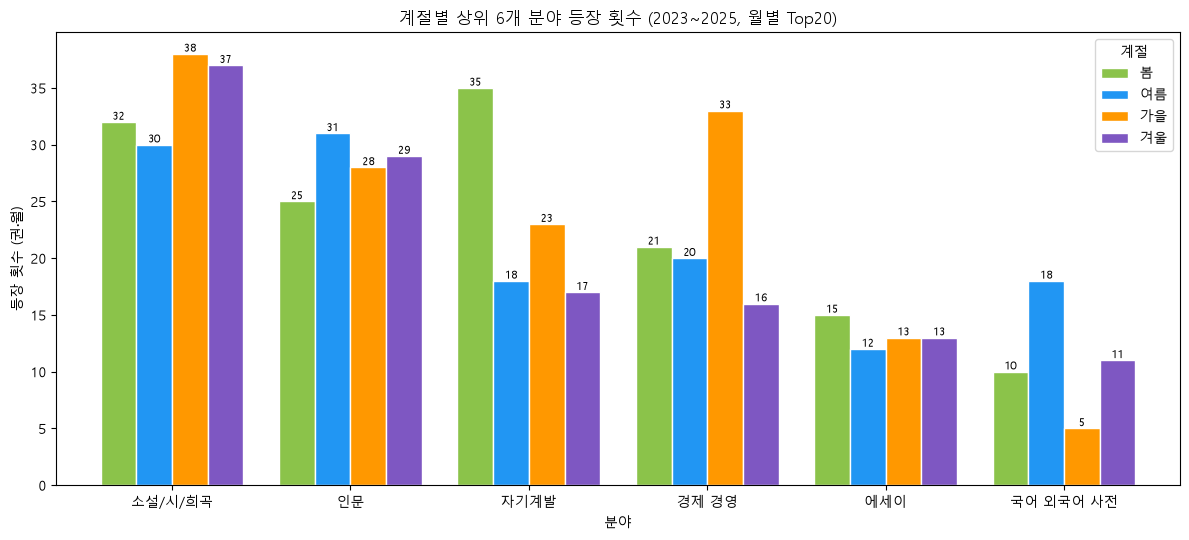

In [17]:
TOP_FIELDS = FIELD_ORDER[:6]
cnt = pd.crosstab(df["분야"], df["계절"]).reindex(index=TOP_FIELDS, columns=SEASONS)

ax = cnt.plot(kind="bar", figsize=(12, 5.5), width=0.8, color=[SEASON_COLORS[s] for s in SEASONS], edgecolor="white")
ax.set_title("계절별 상위 6개 분야 등장 횟수 (2023~2025, 월별 Top20)")
ax.set_xlabel("분야")
ax.set_ylabel("등장 횟수 (권·월)")
ax.legend(title="계절")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
plt.tight_layout()
plt.show()

**해석**
- 상위 6개 분야 중 계절 간 차이가 가장 큰 것은 자기계발(봄 35 vs 겨울 17)과 경제 경영(가을 33 vs 겨울 16)으로, 가장 높은 계절이 가장 낮은 계절의 약 2배입니다.
- 소설/시/희곡(30~38), 인문(25~31), 에세이(12~15)는 계절 간 차이가 작습니다.

### 4-4. 계절별 분야 비율 — 100% 누적 막대

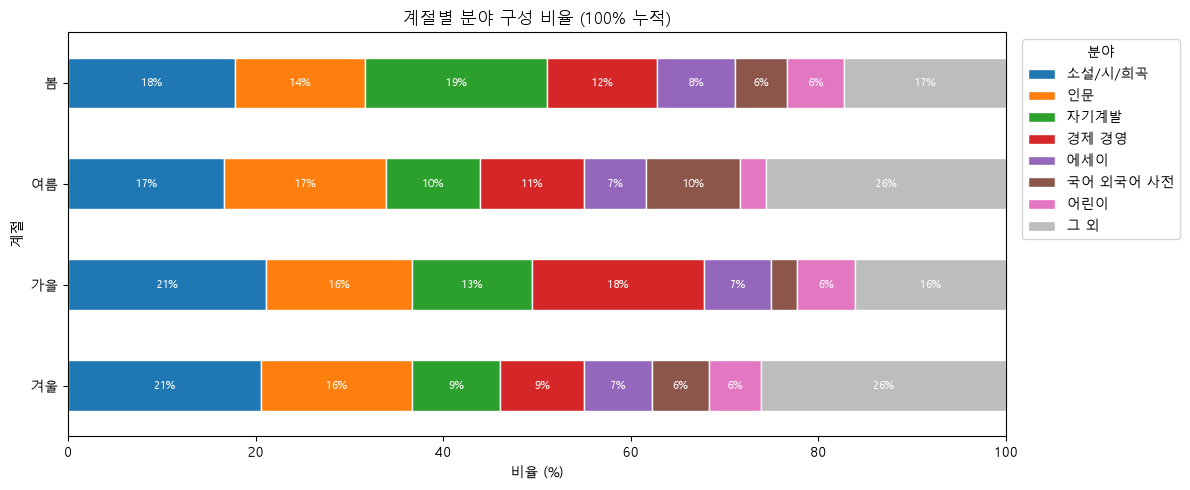

In [18]:
TOP_N_STACK = 7
main_fields = FIELD_ORDER[:TOP_N_STACK]
tmp = df.assign(분야그룹=df["분야"].where(df["분야"].isin(main_fields), "그 외"))
share = (pd.crosstab(tmp["계절"], tmp["분야그룹"], normalize="index") * 100).reindex(index=SEASONS, columns=main_fields + ["그 외"])

colors = list(plt.get_cmap("tab10").colors[:TOP_N_STACK]) + ["#BDBDBD"]
ax = share.plot(kind="barh", stacked=True, figsize=(12, 5), color=colors, edgecolor="white")
ax.set_title("계절별 분야 구성 비율 (100% 누적)")
ax.set_xlabel("비율 (%)")
ax.set_ylabel("계절")
ax.set_xlim(0, 100)
ax.invert_yaxis()
for c in ax.containers:
    labels = [f"{w:.0f}%" if w >= 4 else "" for w in c.datavalues]
    ax.bar_label(c, labels=labels, label_type="center", fontsize=8, color="white")
ax.legend(title="분야", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**해석**
- 봄은 자기계발 19%가 가장 큰 칸이고, 가을은 경제 경영 18%가 눈에 띄게 넓습니다.
- 여름과 겨울은 상위 7개 분야 밖의 '그 외'가 각각 26%로 가장 큽니다. 여름은 수험서 자격증(7.8%)·청소년(4.4%), 겨울은 만화/라이트노벨(11.1%)이 '그 외'를 키웠습니다.

### 4-5. 계절 × 분야 등장 비율 히트맵

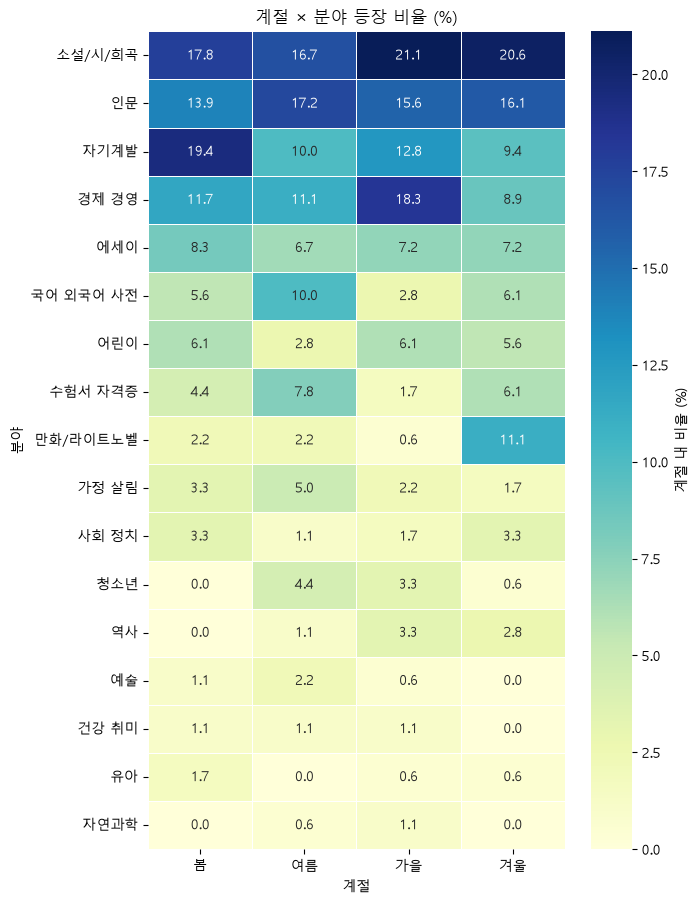

In [19]:
heat = ct_pct[SEASONS]
plt.figure(figsize=(7, 0.45 * len(heat) + 1.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "계절 내 비율 (%)"}, linewidths=0.5)
plt.title("계절 × 분야 등장 비율 (%)")
plt.xlabel("계절")
plt.ylabel("분야")
plt.tight_layout()
plt.show()

**해석**
- 히트맵에서 진한 칸은 소설/시/희곡과 인문 행에 넓게 퍼져 있어, 두 분야가 계절과 상관없이 기본 비중을 차지합니다.
- 계절에 따라 한 칸만 진해지는 분야는 자기계발(봄 19.4%), 경제 경영(가을 18.3%), 만화/라이트노벨(겨울 11.1%), 국어 외국어 사전(여름 10.0%)입니다.
- 청소년·역사·예술·유아·자연과학은 계절마다 0~4.4%로 등장 횟수가 적어서, 비율 차이를 계절 효과로 보기 어렵습니다.

### 4-6. 1월에 자기계발 분야 비중이 더 높은가?

월,1,2,3,4,5,6,7,8,9,10,11,12
자기계발 권수,6.0,5.0,13.0,10.0,12.0,8.0,5.0,5.0,8.0,8.0,7.0,6.0
전체 권수,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0
비율(%),10.0,8.3,21.7,16.7,20.0,13.3,8.3,8.3,13.3,13.3,11.7,10.0


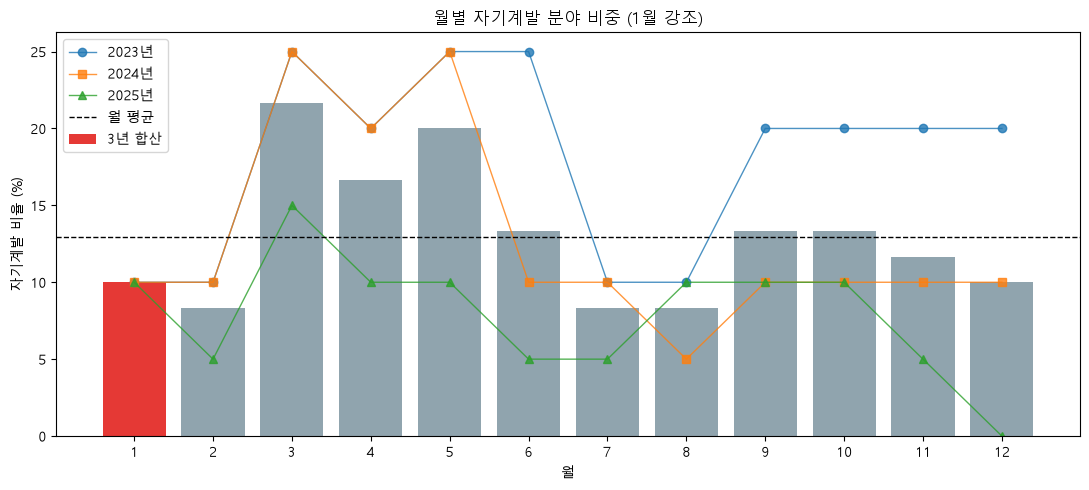

1월 자기계발 비율: 10.0%  /  1월 제외 11개월: 13.2%
1월 순위: 12개월 중 8위


연도,2023,2024,2025
월,,,
1,10.0,10.0,10.0


In [20]:
SELF = "자기계발"
monthly = (df.assign(is_self=df["분야"].eq(SELF))
             .groupby("월")["is_self"].agg(["sum", "count"]))
monthly["비율(%)"] = monthly["sum"] / monthly["count"] * 100
monthly.columns = ["자기계발 권수", "전체 권수", "비율(%)"]
display(monthly.round(1).T)

by_year_month = (df.assign(is_self=df["분야"].eq(SELF))
                   .pivot_table(index="월", columns="연도", values="is_self", aggfunc="mean") * 100)

fig, ax = plt.subplots(figsize=(11, 5))
bar_colors = ["#E53935" if m == 1 else "#90A4AE" for m in monthly.index]
ax.bar(monthly.index, monthly["비율(%)"], color=bar_colors, label="3년 합산")
for y, mk in zip(by_year_month.columns, ["o", "s", "^"]):
    ax.plot(by_year_month.index, by_year_month[y], marker=mk, linewidth=1, alpha=0.8, label=f"{y}년")
ax.axhline(monthly["비율(%)"].mean(), color="black", linestyle="--", linewidth=1, label="월 평균")
ax.set_xticks(range(1, 13))
ax.set_title("월별 자기계발 분야 비중 (1월 강조)")
ax.set_xlabel("월")
ax.set_ylabel("자기계발 비율 (%)")
ax.legend()
plt.tight_layout()
plt.show()

jan = monthly.loc[1, "비율(%)"]
others = df.loc[df["월"] != 1, "분야"].eq(SELF).mean() * 100
print(f"1월 자기계발 비율: {jan:.1f}%  /  1월 제외 11개월: {others:.1f}%")
print(f"1월 순위: 12개월 중 {int(monthly['비율(%)'].rank(ascending=False, method='min')[1])}위")
display(by_year_month.round(1).loc[[1]])

**해석**
- 1월 자기계발 비율은 10.0%(60권 중 6권)로, 1월을 뺀 11개월 평균 13.2%보다 **낮고**, 12개월 중 8위입니다. 3년 모두 1월은 10.0%(20권 중 2권)였습니다.
- '새해 결심 효과로 1월에 자기계발이 많다'는 가설은 이 데이터에서 확인되지 않았습니다.
- 자기계발이 실제로 높은 달은 3월(21.7%), 5월(20.0%), 4월(16.7%)로, 1월이 아니라 **봄**에 몰립니다.

### 4-7. 여름에 소설 분야 비중이 더 높은가?

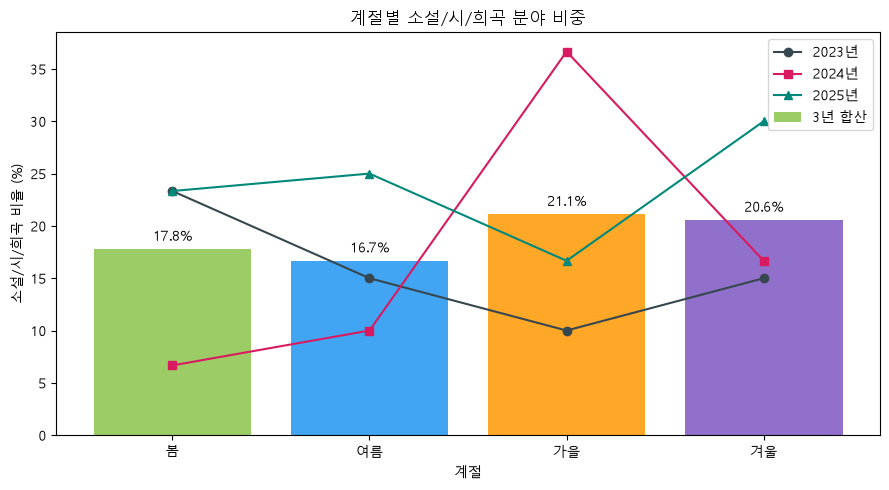

계절
봄     17.8
여름    16.7
가을    21.1
겨울    20.6

연도  2023  2024  2025
계절                  
봄   23.3   6.7  23.3
여름  15.0  10.0  25.0
가을  10.0  36.7  16.7
겨울  15.0  16.7  30.0


In [21]:
NOVEL = "소설/시/희곡"
season_novel = (pd.crosstab(df["계절"], df["분야"].eq(NOVEL), normalize="index") * 100)[True].reindex(SEASONS)
year_season_novel = (df.assign(is_novel=df["분야"].eq(NOVEL))
                       .pivot_table(index="계절", columns="연도", values="is_novel", aggfunc="mean", observed=False) * 100).reindex(SEASONS)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(SEASONS, season_novel.values, color=[SEASON_COLORS[s] for s in SEASONS], alpha=0.85, label="3년 합산")
for y, mk, col in zip(year_season_novel.columns, ["o", "s", "^"], ["#37474F", "#D81B60", "#00897B"]):
    ax.plot(SEASONS, year_season_novel[y], marker=mk, color=col, label=f"{y}년")
for i, v in enumerate(season_novel.values):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
ax.set_title("계절별 소설/시/희곡 분야 비중")
ax.set_xlabel("계절")
ax.set_ylabel("소설/시/희곡 비율 (%)")
ax.legend()
plt.tight_layout()
plt.show()

print(season_novel.round(1).to_string())
print()
print(year_season_novel.round(1))

**해석**
- 3년 합산 소설/시/희곡 비중은 여름 16.7%로 네 계절 중 **가장 낮습니다**(가을 21.1%, 겨울 20.6%, 봄 17.8%). '여름에 소설이 많다'는 가설은 확인되지 않았습니다.
- 연도별로는 변동이 큽니다. 2024년 가을 36.7%는 2024년 10월 소설 12권 중 10권이 한강 작품('소년이 온다', '채식주의자', '작별하지 않는다', '흰' 등)이었던 노벨문학상 효과이고, 2025년은 여름 25.0%로 2025년 안에서 겨울(30.0%) 다음으로 높았습니다.
- 소설 비중의 계절 차이는 계절 자체보다 그해의 특정 사건·화제작에 더 크게 좌우되었습니다.

### 4-8. 연도별로 계절 패턴이 반복되는가? (2023·2024·2025 비교)

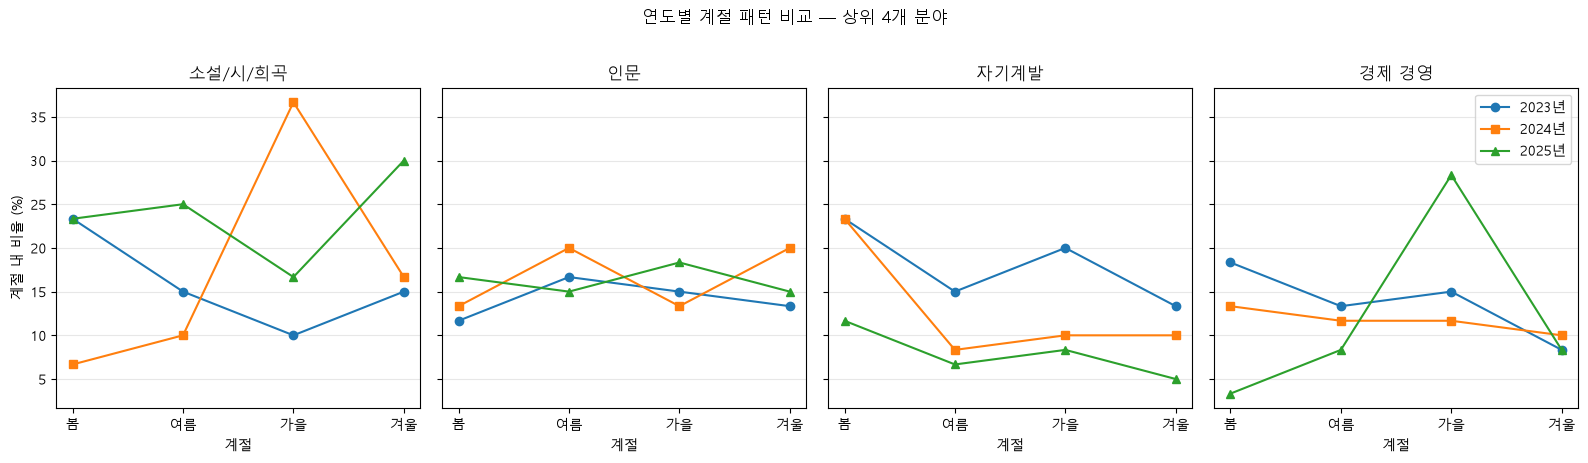

분야       소설/시/희곡    인문  자기계발  경제 경영
연도   계절                            
2023 봄      23.3  11.7  23.3   18.3
     여름     15.0  16.7  15.0   13.3
     가을     10.0  15.0  20.0   15.0
     겨울     15.0  13.3  13.3    8.3
2024 봄       6.7  13.3  23.3   13.3
     여름     10.0  20.0   8.3   11.7
     가을     36.7  13.3  10.0   11.7
     겨울     16.7  20.0  10.0   10.0
2025 봄      23.3  16.7  11.7    3.3
     여름     25.0  15.0   6.7    8.3
     가을     16.7  18.3   8.3   28.3
     겨울     30.0  15.0   5.0    8.3

In [22]:
COMPARE = FIELD_ORDER[:4]
ys = (pd.crosstab([df["연도"], df["계절"]], df["분야"], normalize="index") * 100).reindex(columns=COMPARE)

fig, axes = plt.subplots(1, len(COMPARE), figsize=(16, 4.5), sharey=True)
for ax, field in zip(axes, COMPARE):
    for y, mk in zip([2023, 2024, 2025], ["o", "s", "^"]):
        ax.plot(SEASONS, ys.loc[y, field].reindex(SEASONS).values, marker=mk, label=f"{y}년")
    ax.set_title(field)
    ax.set_xlabel("계절")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("계절 내 비율 (%)")
axes[-1].legend()
fig.suptitle("연도별 계절 패턴 비교 — 상위 4개 분야", y=1.02)
plt.tight_layout()
plt.show()

display(ys.round(1))

**해석**
- 자기계발의 '봄에 높음' 패턴은 2023년(23.3%)과 2024년(23.3%)에는 뚜렷했지만, 2025년에는 봄 11.7%로 약해졌습니다. 2025년은 자기계발 비중이 전체적으로 5.0~11.7%로 낮았습니다.
- 경제 경영의 '가을에 높음'은 2025년 가을(28.3%)에 가장 강하고(트렌드 코리아 2026, 머니 트렌드 2026, 연금·ETF 투자서), 2023·2024년 가을은 각각 15.0%, 11.7%로 다른 계절과 큰 차이가 없습니다.
- 3년 내내 같은 모양으로 반복된 패턴은 없습니다. 3년 합산 결과는 특정 연도의 효과가 섞인 것으로 보아야 합니다.

### 4-9. 스테디셀러 Top 5와 히트작 영향

In [23]:
book_info = df.drop_duplicates("상품번호").set_index("상품번호")[["제목", "저자", "분야"]]
steady = (months_per_book.rename("등장 개월 수").to_frame().join(book_info)
            .sort_values("등장 개월 수", ascending=False))
top5 = steady.head(5)
display(top5)

# 공동 5위가 있는지 확인
fifth = top5["등장 개월 수"].iloc[-1]
print(f"5위 기준 개월 수: {fifth}, 같은 개월 수의 책: {(steady['등장 개월 수'] == fifth).sum()}권")

,등장 개월 수,제목,저자,분야
상품번호,,,,
117014613,21,세이노의 가르침,세이노(SayNo) 저,자기계발
8759796,18,모순,양귀자 저,소설/시/희곡
124043812,17,ETS 토익 정기시험 기출문제집 1000 Vol. 4 RC,ETS 저,국어 외국어 사전
124043802,15,ETS 토익 정기시험 기출문제집 1000 Vol. 4 LC,ETS 저,국어 외국어 사전
136298166,14,어른의 행복은 조용하다,태수 저,에세이


5위 기준 개월 수: 14, 같은 개월 수의 책: 1권


In [24]:
TOP5_IDS = top5.index.tolist()
in_top5 = df["상품번호"].isin(TOP5_IDS)

# 계절별 데이터에서 Top5 책이 차지하는 비율
season_share = pd.DataFrame({
    "계절 전체 행": df.groupby("계절", observed=False).size(),
    "Top5 행": df[in_top5].groupby("계절", observed=False).size(),
})
season_share["Top5 비율(%)"] = season_share["Top5 행"] / season_share["계절 전체 행"] * 100
display(season_share.round(1))

# 책별 × 계절 등장 횟수
display(pd.crosstab(df.loc[in_top5, "제목"], df.loc[in_top5, "계절"]).reindex(columns=SEASONS))

# Top5를 빼도 계절별 분야 비율이 비슷한가?
with_pct = pd.crosstab(df["분야"], df["계절"], normalize="columns") * 100
without_pct = pd.crosstab(df.loc[~in_top5, "분야"], df.loc[~in_top5, "계절"], normalize="columns") * 100
comp = pd.concat({"포함": with_pct, "제외": without_pct}, axis=1).reindex(FIELD_ORDER[:5])
comp = comp.swaplevel(axis=1)[[(s, k) for s in SEASONS for k in ["포함", "제외"]]]
display(comp.round(1))

,계절 전체 행,Top5 행,Top5 비율(%)
계절,,,
봄,180,19,10.6
여름,180,26,14.4
가을,180,19,10.6
겨울,180,21,11.7


계절,봄,여름,가을,겨울
제목,,,,
ETS 토익 정기시험 기출문제집 1000 Vol. 4 LC,3,6,2,4
ETS 토익 정기시험 기출문제집 1000 Vol. 4 RC,4,6,3,4
모순,3,5,6,4
세이노의 가르침,6,6,4,5
어른의 행복은 조용하다,3,3,4,4


계절          봄          여름          가을          겨울      
           포함    제외    포함    제외    포함    제외    포함    제외
분야                                                     
소설/시/희곡  17.8  18.0  16.7  16.2  21.1  19.9  20.6  20.8
인문       13.9  15.5  17.2  20.1  15.6  17.4  16.1  18.2
자기계발     19.4  18.0  10.0   7.8  12.8  11.8   9.4   7.5
경제 경영    11.7  13.0  11.1  13.0  18.3  20.5   8.9  10.1
에세이       8.3   7.5   6.7   5.8   7.2   5.6   7.2   5.7

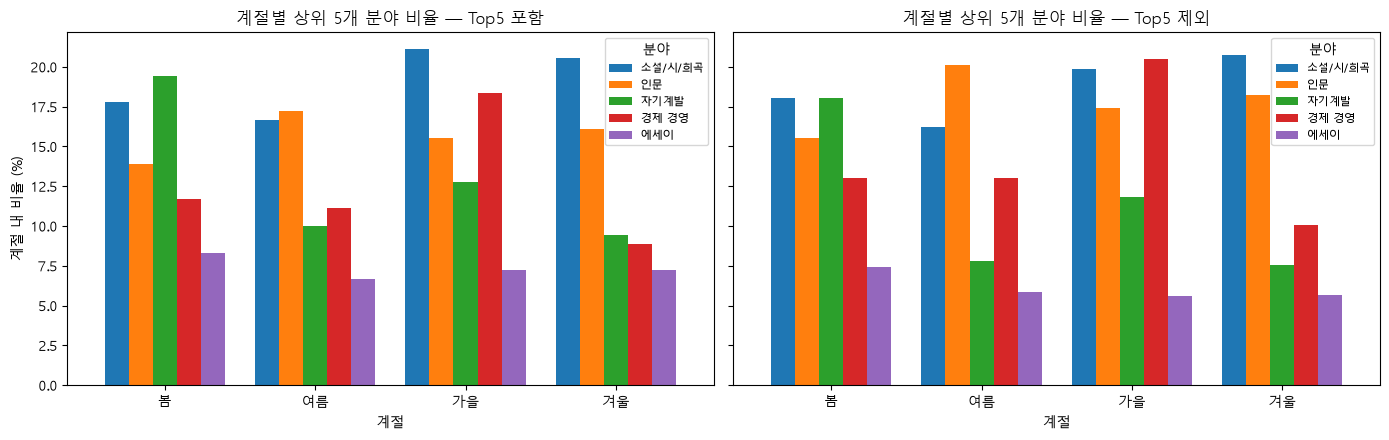

[서로 다른 책 기준 계절 내 분야 비율, %]


계절,봄,여름,가을,겨울
분야,,,,
소설/시/희곡,17.3,15.4,18.7,18.8
인문,12.5,17.3,15.9,12.0
자기계발,15.4,8.7,10.3,6.8
경제 경영,11.5,12.5,19.6,12.0
에세이,6.7,5.8,6.5,6.8


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (label, data) in zip(axes, [("Top5 포함", with_pct), ("Top5 제외", without_pct)]):
    data.reindex(index=FIELD_ORDER[:5], columns=SEASONS).T.plot(kind="bar", ax=ax, width=0.8)
    ax.set_title(f"계절별 상위 5개 분야 비율 — {label}")
    ax.set_xlabel("계절")
    ax.set_ylabel("계절 내 비율 (%)")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="분야", fontsize=8)
plt.tight_layout()
plt.show()

# 서로 다른 책 기준(같은 계절에 여러 달 등장해도 1번만 셈) 비율도 비교
uniq = df.drop_duplicates(["계절", "상품번호"])
uniq_pct = (pd.crosstab(uniq["분야"], uniq["계절"], normalize="columns") * 100).reindex(index=FIELD_ORDER[:5], columns=SEASONS)
print("[서로 다른 책 기준 계절 내 분야 비율, %]")
display(uniq_pct.round(1))

**해석**
- 가장 많은 달에 등장한 책은 세이노의 가르침(21개월, 자기계발), 모순(18개월, 소설), ETS 토익 기출 Vol.4 RC(17개월)·LC(15개월, 국어 외국어 사전), 어른의 행복은 조용하다(14개월, 에세이)입니다. 이 5권이 계절 데이터의 10.6~14.4%를 차지하며, 여름이 14.4%로 가장 높습니다.
- Top 5를 빼고 다시 계산해도 각 계절의 1위 분야와 '봄 자기계발 18.0%, 가을 경제 경영 20.5%' 같은 큰 흐름은 유지됩니다. 히트작 한 권이 결론을 뒤집지는 않습니다.
- 다만 여름 자기계발(10.0% → 7.8%)과 여름 국어 외국어 사전(토익 RC·LC가 여름에 각 6회)은 Top 5의 영향을 받습니다. 겨울 만화/라이트노벨 20회 중 18회가 2023년 1~2월 '슬램덩크' 시리즈(영화 개봉 효과)라는 점도 하나의 화제작이 결과를 크게 바꾼 예입니다.
- 서로 다른 책 기준으로 세어도 자기계발은 봄(15.4%), 경제 경영은 가을(19.6%)이 가장 높아, 두 패턴은 한 권의 반복 등장이 아니라 여러 권에서 나타납니다.

## 5. 결론과 한계

### 결론
1. **계절과 상관없이 가장 많이 등장하는 분야는 소설/시/희곡입니다.** 3년 전체 137회(19.0%)로 1위이며, 가을(21.1%)·겨울(20.6%)에는 계절 1위, 봄·여름에도 2위입니다. 인문(15.7%)도 모든 계절에서 Top 3 안에 있습니다.
2. **봄에는 자기계발이 1위입니다.** 봄 19.4%(35회)로 여름 10.0%, 겨울 9.4%의 약 2배이며, 월별로는 3월 21.7%가 가장 높습니다. 반대로 '1월에 자기계발이 많다'는 가설은 확인되지 않았습니다(1월 10.0%, 12개월 중 8위).
3. **가을에는 경제 경영이 늘어납니다.** 가을 18.3%(33회)로 겨울(8.9%)의 2배 수준이지만, 이 차이는 대부분 2025년 가을(28.3%, 다음 해 트렌드 전망서·투자서)에서 나왔습니다.
4. **'여름에 소설이 많다'는 가설은 확인되지 않았습니다.** 여름 소설 비중 16.7%는 네 계절 중 가장 낮고, 여름에는 인문(17.2%)이 1위, 토익·한국사 등 수험서 성격의 분야가 상대적으로 많습니다.
5. **계절 패턴보다 연도별 화제작의 영향이 큽니다.** 2023년 겨울 '슬램덩크'(만화 20회 중 18회), 2024년 가을 노벨문학상 수상 후 한강 작품(가을 소설 36.7%) 같은 사건이 특정 계절 수치를 크게 바꾸었고, 3년 내내 반복된 계절 패턴은 확인되지 않았습니다.

### 한계
- **종합 베스트셀러만 사용**: 국내도서 종합 순위라 분야별 내부 변화(예: 소설 분야 안에서의 계절성)는 보지 못합니다.
- **상위 20위만 수집**: 한 달에 20권이라 한두 권만 달라져도 비율이 5~10%p씩 움직입니다. 계절당 180행, 연도·계절당 60행으로 표본이 작습니다.
- **분야 분류 기준**: 상세 페이지의 첫 번째 카테고리 경로의 대분류를 사용했습니다. 한 책이 여러 분류에 걸쳐 있어도(예: 인문 + 에세이) 하나만 반영되며, YES24의 분류 방식에 결과가 의존합니다.
- **히트작 영향**: 한 권이 최대 21개월 등장하고, Top 5가 계절 데이터의 10.6~14.4%를 차지합니다. 화제작·시리즈물(슬램덩크, 한강 작품)이 특정 계절을 크게 흔듭니다.
- **겨울 묶음 문제**: 겨울을 같은 연도의 1·2·12월로 묶었기 때문에 실제로 이어지는 겨울(예: 2023년 12월 ~ 2024년 2월)과 다릅니다. 또한 2023년 겨울은 2023년 1·2월과 12월이 섞여 있어, 연도별 비교에서 겨울 값 해석에 주의해야 합니다.
- **기간 3년**: 계절이 3번씩만 반복되어, 우연인지 반복되는 패턴인지 통계적으로 판단하기 어렵습니다.

### 다음 분석 제안
- 수집 기간을 늘리고(예: 2015년~), 순위를 50위·100위까지 넓혀 표본을 키운 뒤 계절 × 분야 카이제곱 검정으로 계절 효과를 검정합니다.
- 겨울을 12월~다음 해 2월로 묶는 '시즌 연도' 기준으로 다시 집계해 결과가 달라지는지 비교합니다.
- 순위 가중치(1위=20점 … 20위=1점)를 주거나, 새로 진입한 책만 세어 장기 베스트셀러의 영향을 줄인 분석을 추가합니다.
- 영화·드라마 개봉, 문학상 발표, 수능·토익 일정 같은 외부 사건 데이터를 붙여 화제작 효과와 계절 효과를 나누어 봅니다.